# LAB3 - Bài 1

## Câu a

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics

import keras
from keras.models import Sequential
from keras.layers import Dense, Input

In [2]:
# Cố định seed để kết quả huấn luyện Neural Network có thể lặp lại
keras.utils.set_random_seed(42)

In [3]:
# Đọc bộ dữ liệu Iris từ sklearn
iris = load_iris()

## Câu b

In [4]:
# Tên các thuộc tính, thuộc tính phân lớp
print("Feature names:", iris.feature_names)
print("Target names:", iris.target_names)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']


Đặng Phan Duy - 6451071010

In [5]:
# Số lượng mẫu, số lượng thuộc tính
print("Data shape:", iris.data.shape)
print("Target shape:", iris.target.shape)

Data shape: (150, 4)
Target shape: (150,)


Đặng Phan Duy - 6451071010

In [6]:
# 5 mẫu dữ liệu đầu tiên
print("Data:\n", iris.data[:5])
print("Target:", iris.target[:5])

Data:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
Target: [0 0 0 0 0]


Đặng Phan Duy - 6451071010

In [7]:
# Thống kê count, mean, std, min, max, tứ phân vị của bộ dữ liệu
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Đặng Phan Duy - 6451071010

## Câu c

In [8]:
X = iris.data
Y = iris.target

# Chuẩn hóa về đoạn [0,1]: chia mỗi giá trị cho giá trị lớn nhất của cột tương ứng
X_max = X.max(axis=0)
X = X / X_max

print("Max của từng cột:", X_max)
print("X sau khi chuẩn hóa:\n", X[:5])
print("Min:", X.min(), "- Max:", X.max())

Max của từng cột: [7.9 4.4 6.9 2.5]
X sau khi chuẩn hóa:
 [[0.64556962 0.79545455 0.20289855 0.08      ]
 [0.62025316 0.68181818 0.20289855 0.08      ]
 [0.59493671 0.72727273 0.1884058  0.08      ]
 [0.58227848 0.70454545 0.2173913  0.08      ]
 [0.63291139 0.81818182 0.20289855 0.08      ]]
Min: 0.04 - Max: 1.0


Đặng Phan Duy - 6451071010

## Câu d

In [9]:
# Chia dữ liệu thành tập train và tập test theo tỷ lệ 8:2
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape, "- y_train:", y_train.shape)
print("X_test:", X_test.shape, "- y_test:", y_test.shape)

X_train: (120, 4) - y_train: (120,)
X_test: (30, 4) - y_test: (30,)


Đặng Phan Duy - 6451071010

## Câu e

In [10]:
# Huấn luyện mô hình Cây quyết định trên tập train
clf = DecisionTreeClassifier(random_state=0)
clf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Đặng Phan Duy - 6451071010

In [11]:
# Dự đoán nhãn lớp cho tập test
tree_pred = clf.predict(X_test)
print("Predict:", tree_pred)
print("Actual: ", y_test)

Predict: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Actual:  [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


Đặng Phan Duy - 6451071010

In [12]:
# Tính Accuracy, Precision, Recall, F1-score trên tập test
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:\n", metrics.classification_report(y_test, tree_pred, target_names=iris.target_names))

Accuracy: 1.0
Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Đặng Phan Duy - 6451071010

In [13]:
tree_cm = metrics.confusion_matrix(y_test, tree_pred)

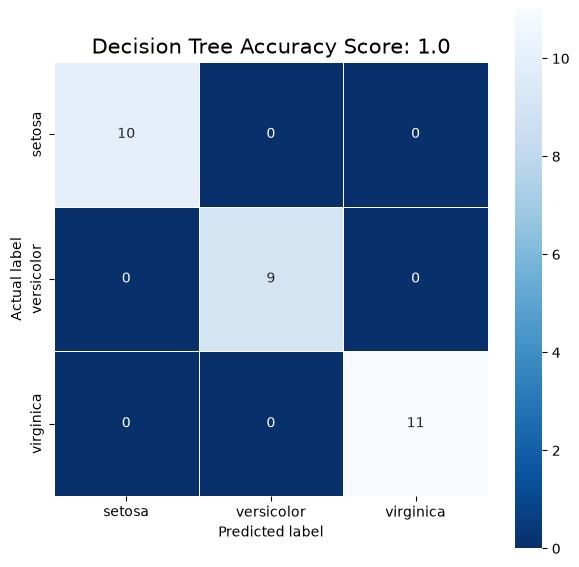

In [14]:
plt.figure(figsize=(7,7))
sns.heatmap(tree_cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Blues_r',
            xticklabels=iris.target_names, yticklabels=iris.target_names);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Decision Tree Accuracy Score: {0}'.format(tree_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

## Câu f

In [15]:
# Huấn luyện mô hình Naive Bayes trên tập train
gnb = GaussianNB()
gnb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[40.,41.,39.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.33,0.34,0.33]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](3,)","[0,1,2]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,8.98e-11
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 4)","[[0.63,0.78,0.21,0.1 ], [0.75,0.63,0.61,0.53], [0.83,0.67,0.8 ,0.8 ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 4)","[[0. ,0.01,0. ,0. ], [0. ,0.01,0. ,0.01], [0.01,0.01,0.01,0.01]]"


Đặng Phan Duy - 6451071010

In [16]:
# Dự đoán nhãn lớp cho tập test
bayes_pred = gnb.predict(X_test)
print("Predict:", bayes_pred)
print("Actual: ", y_test)

Predict: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Actual:  [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


Đặng Phan Duy - 6451071010

In [17]:
# Tính Accuracy, Precision, Recall, F1-score trên tập test
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred, target_names=iris.target_names))

Accuracy: 1.0
Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Đặng Phan Duy - 6451071010

In [18]:
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

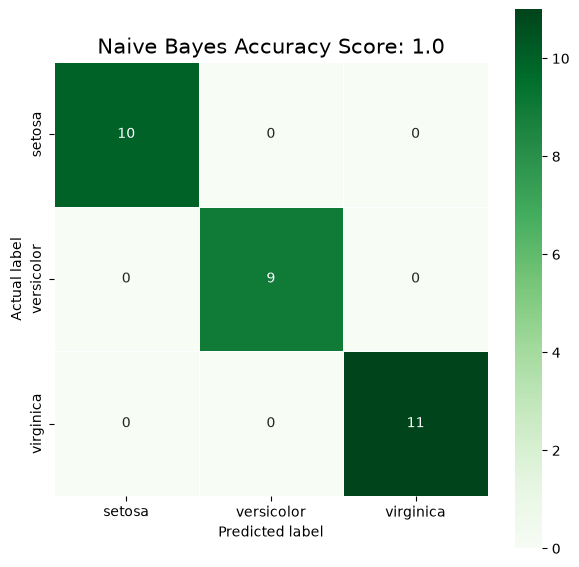

In [19]:
plt.figure(figsize=(7,7))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Greens',
            xticklabels=iris.target_names, yticklabels=iris.target_names);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Naive Bayes Accuracy Score: {0}'.format(bayes_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

## Câu g

In [20]:
# Huấn luyện mô hình K Nearest Neighbors trên tập train
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


Đặng Phan Duy - 6451071010

In [21]:
# Dự đoán nhãn lớp cho tập test
knn_pred = knn.predict(X_test)
print("Predict:", knn_pred)
print("Actual: ", y_test)

Predict: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Actual:  [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


Đặng Phan Duy - 6451071010

In [22]:
# Tính Accuracy, Precision, Recall, F1-score trên tập test
knn_score = metrics.accuracy_score(y_test, knn_pred)
print("Accuracy:", knn_score)
print("Report:\n", metrics.classification_report(y_test, knn_pred, target_names=iris.target_names))

Accuracy: 1.0
Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Đặng Phan Duy - 6451071010

In [23]:
knn_cm = metrics.confusion_matrix(y_test, knn_pred)

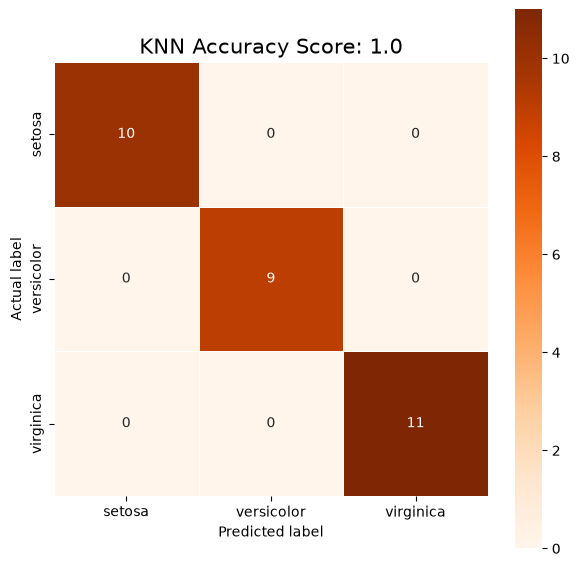

In [24]:
plt.figure(figsize=(7,7))
sns.heatmap(knn_cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Oranges',
            xticklabels=iris.target_names, yticklabels=iris.target_names);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'KNN Accuracy Score: {0}'.format(knn_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

## Câu h

In [25]:
# Xây dựng Neural Network gồm 02 hidden layers và 01 output layer
model = Sequential([
    Input(shape=(X_train.shape[1],)),                       # 4 thuộc tính
    Dense(10, activation='relu'),                           # hidden layer 1: 10 neuron
    Dense(20, activation='relu'),                           # hidden layer 2: 20 neuron
    Dense(len(iris.target_names), activation='softmax')     # output layer: 3 class
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 10)                  │              50 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 20)                  │             220 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │              63 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 333 (1.30 KB)

 Trainable params: 333 (1.30 KB)

 Non-trainable params: 0 (0.00 B)

Đặng Phan Duy - 6451071010

In [26]:
# Biên dịch mô hình
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [27]:
# Huấn luyện mô hình trên tập train
history = model.fit(X_train, y_train, epochs=100, batch_size=1, verbose=1)

Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3917 - loss: 1.0245
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7750 - loss: 0.8985
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9083 - loss: 0.7561
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8833 - loss: 0.6013
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9000 - loss: 0.4940
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9500 - loss: 0.4278
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9583 - loss: 0.3835
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9583 - loss: 0.3494
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9583 - loss: 0.3210
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9583 - loss: 0.2966
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9583 - loss: 0.2745
Epoch 12/100
120/120 ━━━━━━━━━━━━━━━━━━━━

Đặng Phan Duy - 6451071010

In [28]:
# Dự đoán xác suất cho mỗi mẫu và mỗi class, chọn class có xác suất lớn nhất
nn_prob = model.predict(X_test)
nn_pred = np.argmax(nn_prob, axis=1)
print("Predict:", nn_pred)
print("Actual: ", y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
Predict: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Actual:  [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


Đặng Phan Duy - 6451071010

In [29]:
# Tính Accuracy, Precision, Recall, F1-score trên tập test
nn_score = metrics.accuracy_score(y_test, nn_pred)
print("Accuracy:", nn_score)
print("Report:\n", metrics.classification_report(y_test, nn_pred, target_names=iris.target_names))

Accuracy: 1.0
Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Đặng Phan Duy - 6451071010

In [30]:
nn_cm = metrics.confusion_matrix(y_test, nn_pred)

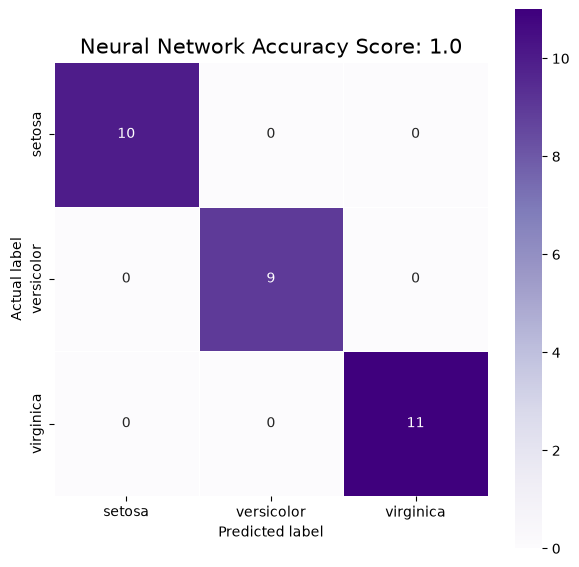

In [31]:
plt.figure(figsize=(7,7))
sns.heatmap(nn_cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Purples',
            xticklabels=iris.target_names, yticklabels=iris.target_names);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Neural Network Accuracy Score: {0}'.format(nn_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

## Câu i

In [32]:
# 03 mẫu dữ liệu mới, chuẩn hóa giống như dữ liệu huấn luyện (chia cho max của từng cột)
X_new = np.array([[6.2, 2.9, 4.3, 1.3],
                  [5.1, 3.5, 1.4, 0.2],
                  [7.3, 2.8, 6.4, 2.1]])
X_new_scaled = X_new / X_max

new_pred = pd.DataFrame({
    'Sample': [str(s) for s in X_new.tolist()],
    'Decision Tree': iris.target_names[clf.predict(X_new_scaled)],
    'Naive Bayes': iris.target_names[gnb.predict(X_new_scaled)],
    'KNN': iris.target_names[knn.predict(X_new_scaled)],
    'Neural Network': iris.target_names[np.argmax(model.predict(X_new_scaled), axis=1)]
})
new_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


,Sample,Decision Tree,Naive Bayes,KNN,Neural Network
0,"[6.2, 2.9, 4.3, 1.3]",versicolor,versicolor,versicolor,versicolor
1,"[5.1, 3.5, 1.4, 0.2]",setosa,setosa,setosa,setosa
2,"[7.3, 2.8, 6.4, 2.1]",virginica,virginica,virginica,virginica


Đặng Phan Duy - 6451071010

## Câu j

In [33]:
preds = [tree_pred, bayes_pred, knn_pred, nn_pred]
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Naive Bayes', 'KNN', 'Neural Network'],
    'Accuracy': [tree_score, bayes_score, knn_score, nn_score],
    'Precision (macro)': [metrics.precision_score(y_test, p, average='macro') for p in preds],
    'Recall (macro)': [metrics.recall_score(y_test, p, average='macro') for p in preds],
    'F1 (macro)': [metrics.f1_score(y_test, p, average='macro') for p in preds]
})
results

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Decision Tree,1.0,1.0,1.0,1.0
1,Naive Bayes,1.0,1.0,1.0,1.0
2,KNN,1.0,1.0,1.0,1.0
3,Neural Network,1.0,1.0,1.0,1.0


Đặng Phan Duy - 6451071010

Nhận xét:

- Trên tập test (30 mẫu: 10 setosa, 9 versicolor, 11 virginica), cả 4 mô hình Decision Tree, Naïve Bayes, KNN và Neural Network đều đạt Accuracy = 1.0; Precision, Recall, F1-score của cả 3 lớp đều bằng 1.00, confusion matrix chỉ có giá trị trên đường chéo chính (không có mẫu nào bị phân lớp sai).
- Kết quả cao như vậy là do bộ dữ liệu Iris nhỏ, sạch, cân bằng (mỗi lớp 50 mẫu) và các lớp tách biệt khá rõ: setosa tách hoàn toàn khỏi hai lớp còn lại theo kích thước cánh hoa, chỉ có versicolor và virginica là hơi chồng lấn nhau. Với cách chia train/test này (random_state=42), các mẫu nằm ở vùng chồng lấn trong tập test đều được cả 4 mô hình phân lớp đúng.
- Với 03 mẫu dữ liệu mới ở câu i, cả 4 mô hình cho kết quả giống nhau: versicolor, setosa, virginica.
- Vì tập test chỉ có 30 mẫu nên kết quả 100% chưa đủ để kết luận mô hình nào tốt hơn; với cách chia dữ liệu khác thì kết quả có thể thay đổi (thường dao động khoảng 0.93 - 1.0). Muốn so sánh đáng tin cậy hơn cần dùng k-fold cross validation (như bài 4).
- Về chi phí: Decision Tree, Naïve Bayes và KNN huấn luyện gần như tức thời và dễ giải thích; Neural Network phải huấn luyện 100 epoch với batch_size = 1 (12000 lần cập nhật trọng số) nên tốn thời gian hơn nhiều mà không cho kết quả tốt hơn. Với bộ dữ liệu nhỏ và đơn giản như Iris, các mô hình đơn giản là đủ; Neural Network phù hợp hơn với dữ liệu lớn và phức tạp (ví dụ MNIST ở bài 2).